# C1 sub-objective 3: context strategies (accuracy vs efficiency)

**Question:** how much of the conversation does the intent model need to see?
Sending more context costs more tokens and time. Does it buy accuracy?

Six ways to build the model input at each user turn:

| Strategy | What the model reads |
|---|---|
| `current_only` | only the current message |
| `window_2` | the previous message + the current one |
| `window_3` | the 2 previous messages + the current one |
| `keyword_summary` | English words and names (EN/NE tags) from earlier messages + the current message |
| `structured_state` | the previous intent and filled slots (e.g. `intent: nic_update \| district: Matara`) + the current message |
| `full_history` | every user message so far (the approach used in `c1_xlmr_train.ipynb`) |

**Sessions:** most dialogues have only 2–3 user turns, too short for the strategies to differ.
So 2–4 dialogues are joined into one longer **session**, the way a citizen asks about an NIC
and then a passport in the same chat. The joins create realistic intent switches.
The original short dialogues are also scored.

For each strategy, an XLM-R model and a TF-IDF model are trained, then measured on:
- accuracy and macro-F1
- accuracy at intent-switch turns
- input tokens per turn
- latency on GPU and CPU

**Before running:** Runtime → Change runtime type → **T4 GPU**. Then Runtime → Run all.
- Upload `silver_tokens.jsonl`, `gold_tokens.jsonl` and `fresh_tokens.jsonl` when asked.
- Allow Google Drive access when asked. Progress is saved there, so if Colab disconnects,
  **Run all** again and it continues where it stopped.
- Takes about 60–80 minutes for 3 seeds.

In [ ]:
# Settings
import json, os, random, time, collections, statistics
import numpy as np
import torch
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

MODEL = os.environ.get("C1_MODEL", "xlm-roberta-base")
SEEDS = [int(s) for s in os.environ.get("C1_SEEDS", "1,2,42").split(",")]   # use [1] for a quick test
EPOCHS = int(os.environ.get("C1_EPOCHS", 15))   # run 1 used 6 and was under-trained (dev score still rising)
BATCH, MAX_LEN, LR, DEV_SHARE = 16, 128, 3e-5, 0.1
STRATEGIES = ["current_only", "window_2", "window_3", "keyword_summary", "structured_state", "full_history"]
SESSION_SIZES = (2, 3, 4)       # dialogues joined into one session
KEYWORDS_MAX = 12               # keyword_summary keeps at most this many earlier keywords
STATE_NOISE = 0.2               # structured_state training: share of turns where the previous intent is randomised
SEP = " </s> "
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| model:", MODEL, "| seeds:", SEEDS, "| epochs:", EPOCHS)
if DEVICE == "cpu" and MODEL == "xlm-roberta-base":
    print("WARNING: no GPU. Runtime -> Change runtime type -> T4 GPU, then rerun.")


def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

device: cuda | model: xlm-roberta-base | seeds: [1, 2, 42] | epochs: 15


In [ ]:
# Data upload + Google Drive (for saving progress)
DATA_DIR = os.environ.get("C1_DATA", "/content/c1")
os.makedirs(DATA_DIR, exist_ok=True)
NEEDED = ["silver_tokens.jsonl", "gold_tokens.jsonl", "fresh_tokens.jsonl"]
missing = [f for f in NEEDED if not os.path.exists(os.path.join(DATA_DIR, f))]
if missing:
    print("Please upload:", missing)
    from google.colab import files
    for name, content in files.upload().items():
        open(os.path.join(DATA_DIR, os.path.basename(name)), "wb").write(content)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = "/content/drive/MyDrive/c1_context"
except Exception as e:
    print("Drive not available, saving next to the data instead:", e)
    OUT_DIR = os.path.join(DATA_DIR, "c1_context")
os.makedirs(OUT_DIR, exist_ok=True)
RESULTS_PATH = os.path.join(OUT_DIR, f"c1_context_results_e{EPOCHS}.json")   # one file per epoch setting
print("progress and results are saved to", RESULTS_PATH)


def read_jsonl(name):
    with open(os.path.join(DATA_DIR, name), encoding="utf-8") as fh:
        return [json.loads(l) for l in fh if l.strip()]


silver, gold, fresh = (read_jsonl(f) for f in NEEDED)
INTENTS = sorted({r["intent"] for r in silver})
t2i = {l: i for i, l in enumerate(INTENTS)}; i2t = {i: l for l, i in t2i.items()}
print(f"silver {len(silver)} turns | gold {len(gold)} | fresh {len(fresh)} | intents: {INTENTS}")

Please upload: ['silver_tokens.jsonl', 'gold_tokens.jsonl', 'fresh_tokens.jsonl']


Saving fresh_tokens.jsonl to fresh_tokens.jsonl
Saving gold_tokens.jsonl to gold_tokens.jsonl
Saving silver_tokens.jsonl to silver_tokens.jsonl
Mounted at /content/drive
progress and results are saved to /content/drive/MyDrive/c1_context/c1_context_results_e15.json
silver 726 turns | gold 142 | fresh 50 | intents: ['birth_cert_copy', 'death_cert_copy', 'marriage_registration', 'nic_new', 'nic_replace_lost', 'nic_update', 'passport_new', 'passport_renew']


In [ ]:
# Sessions: join 2-4 dialogues so that conversations get long enough for the strategies to differ


def dialogues(rows):
    by = collections.defaultdict(list)
    for r in rows:
        by[r["dialogue_id"]].append(r)
    return {d: sorted(v, key=lambda r: r["turn"]) for d, v in by.items()}


def original_sessions(rows):
    return [v for _, v in sorted(dialogues(rows).items())]


def stitched_sessions(rows, seed):
    by = dialogues(rows)
    ids = sorted(by)
    rng = random.Random(seed)
    rng.shuffle(ids)
    out, i = [], 0
    while i < len(ids):
        k = rng.choice(SESSION_SIZES)
        out.append([r for d in ids[i:i + k] for r in by[d]])
        i += k
    return out


# test sessions are fixed (seed 0) so every strategy and seed is scored on the same sessions
TEST_SETS = {
    "gold_original": original_sessions(gold), "gold_sessions": stitched_sessions(gold, 0),
    "fresh_original": original_sessions(fresh), "fresh_sessions": stitched_sessions(fresh, 0),
}
for k, v in TEST_SETS.items():
    lens = [len(s) for s in v]
    print(f"{k:16s} {len(v):4d} sessions | user turns per session: mean {np.mean(lens):.1f}, max {max(lens)}")

gold_original      70 sessions | user turns per session: mean 2.0, max 4
gold_sessions      22 sessions | user turns per session: mean 6.5, max 9
fresh_original     23 sessions | user turns per session: mean 2.2, max 3
fresh_sessions      8 sessions | user turns per session: mean 6.2, max 8


In [ ]:
# The six strategies: how the model input is built at each turn


def words_of_type(rows, keep):
    out = []
    for r in rows:
        for w, t in zip(r["tokens"], r["lang_tags"]):
            if t in keep:
                out.append(w)
    return out


def slots_so_far(rows):
    """Slot values mentioned in earlier turns (latest value wins), from the entity tags."""
    slots = {}
    for r in rows:
        cur_type, words = None, []
        for w, t in list(zip(r["tokens"], r["ner_tags"])) + [("", "O")]:
            if t.startswith("I-") and t[2:] == cur_type:
                words.append(w); continue
            if cur_type:
                slots[cur_type] = " ".join(words)
            cur_type, words = (t[2:], [w]) if t != "O" else (None, [])
    return slots


def build_input(strategy, prev, cur, prev_intent):
    """prev: earlier user turns in this session (oldest first); cur: the current turn;
    prev_intent: the intent of the previous turn (gold when training, the model's own prediction when testing)."""
    texts = [r["text"] for r in prev] + [cur["text"]]
    if strategy == "current_only":
        return cur["text"]
    if strategy.startswith("window_"):
        return SEP.join(texts[-int(strategy.split("_")[1]):])
    if strategy == "full_history":
        return SEP.join(texts)
    if strategy == "keyword_summary":
        seen, kw = set(), []
        for w in reversed(words_of_type(prev, ("EN", "NE"))):       # most recent first, no repeats
            if w.lower() not in seen:
                seen.add(w.lower()); kw.append(w)
        kw = list(reversed(kw[:KEYWORDS_MAX]))
        return ("keywords: " + " ".join(kw) + SEP + cur["text"]) if kw else cur["text"]
    if strategy == "structured_state":
        if not prev:
            return cur["text"]
        state = f"intent: {prev_intent or 'none'}" + "".join(f" | {k}: {v}" for k, v in sorted(slots_so_far(prev).items()))
        return state + SEP + cur["text"]
    raise ValueError(strategy)


def training_examples(sessions, strategy, rng):
    xs, ys = [], []
    for s in sessions:
        for pos, cur in enumerate(s):
            prev_intent = s[pos - 1]["intent"] if pos else None
            if strategy == "structured_state" and prev_intent and rng.random() < STATE_NOISE:
                prev_intent = rng.choice(INTENTS)     # teaches the model not to blindly copy the previous intent
            if cur["intent"] in t2i:
                xs.append(build_input(strategy, s[:pos], cur, prev_intent)); ys.append(t2i[cur["intent"]])
    return xs, ys


def run_sessions(predict_fn, sessions, strategy):
    """Goes through all sessions turn by turn. structured_state uses the model's own previous prediction."""
    out, prev_pred = [], [None] * len(sessions)
    for pos in range(max(len(s) for s in sessions)):
        live = [(i, s) for i, s in enumerate(sessions) if len(s) > pos]
        inputs = [build_input(strategy, s[:pos], s[pos], prev_pred[i]) for i, s in live]
        preds = predict_fn(inputs)
        for (i, s), x, p in zip(live, inputs, preds):
            prev_pred[i] = p
            out.append({"session": i, "pos": pos, "input": x, "gold": s[pos]["intent"], "pred": p,
                        "prev_gold": s[pos - 1]["intent"] if pos else None, "id": f"{s[pos]['dialogue_id']}/{s[pos]['turn']}"})
    return out


# example: one gold session through every strategy
demo = TEST_SETS["gold_sessions"][0]
for st in STRATEGIES:
    print(f"\n[{st}] turn {len(demo)}:\n  {build_input(st, demo[:-1], demo[-1], demo[-2]['intent'] if len(demo) > 1 else None)}")


[current_only] turn 6:
  what documents do I need for a building permit? list ekak denna puluwanda

[window_2] turn 6:
  අද කොළඹ වහිනවද? </s> what documents do I need for a building permit? list ekak denna puluwanda

[window_3] turn 6:
  ගාල්ල </s> අද කොළඹ වහිනවද? </s> what documents do I need for a building permit? list ekak denna puluwanda

[keyword_summary] turn 6:
  keywords: police clearance visa Australia Canada ගාල්ල කොළඹ </s> what documents do I need for a building permit? list ekak denna puluwanda

[structured_state] turn 6:
  intent: out_of_scope | district: ගාල්ල | purpose: Canada visa </s> what documents do I need for a building permit? list ekak denna puluwanda

[full_history] turn 6:
  police clearance ekak ganna one Canada visa ekata </s> ne ne, Australia, Canada nemei </s> තනියම කුඩා ව්‍යාපාරයක් ලියාපදිංචි කරන්න ඕනේ </s> ගාල්ල </s> අද කොළඹ වහිනවද? </s> what documents do I need for a building permit? list ekak denna puluwanda


In [ ]:
# Training, prediction and scoring helpers
tok = AutoTokenizer.from_pretrained(MODEL)
tok.truncation_side = "left"     # if the input is too long, drop the OLDEST text, never the current message


def n_tokens(text):
    return len(tok(text, truncation=False)["input_ids"])


def collate(batch):
    n = max(len(b["input_ids"]) for b in batch)
    pad = tok.pad_token_id
    return {"input_ids": torch.tensor([b["input_ids"] + [pad] * (n - len(b["input_ids"])) for b in batch]),
            "attention_mask": torch.tensor([b["attention_mask"] + [0] * (n - len(b["attention_mask"])) for b in batch]),
            "labels": torch.tensor([b["labels"] for b in batch])}


def encode(xs, ys):
    enc = [tok(x, truncation=True, max_length=MAX_LEN) for x in xs]
    return [{"input_ids": e["input_ids"], "attention_mask": e["attention_mask"], "labels": y} for e, y in zip(enc, ys)]


@torch.no_grad()
def xlmr_predict(model, inputs, bs=32):
    model.eval(); preds = []
    for i in range(0, len(inputs), bs):
        enc = tok(inputs[i:i + bs], truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt")
        logits = model(input_ids=enc["input_ids"].to(model.device), attention_mask=enc["attention_mask"].to(model.device)).logits
        preds += [i2t[x] for x in logits.argmax(-1).cpu().tolist()]
    return preds


def macro_f1(golds, preds):
    f1s = []
    for l in INTENTS:
        tp = sum(g == l and p == l for g, p in zip(golds, preds))
        fp = sum(g != l and p == l for g, p in zip(golds, preds))
        fn = sum(g == l and p != l for g, p in zip(golds, preds))
        pr = tp / (tp + fp) if tp + fp else 0.0
        rc = tp / (tp + fn) if tp + fn else 0.0
        f1s.append(2 * pr * rc / (pr + rc) if pr + rc else 0.0)
    return sum(f1s) / len(f1s)


def train_xlmr(xs, ys, dev_fn, seed):
    set_seed(seed)
    model = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=len(INTENTS), id2label=i2t, label2id=t2i).to(DEVICE)
    dl = DataLoader(encode(xs, ys), batch_size=BATCH, shuffle=True, collate_fn=collate)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    steps = len(dl) * EPOCHS
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
    best, best_state, hist = -1, None, []
    for ep in range(1, EPOCHS + 1):
        model.train(); t0, total = time.time(), 0.0
        for b in dl:
            b = {k: v.to(DEVICE) for k, v in b.items()}
            loss = model(**b).loss
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step(); opt.zero_grad()
            total += loss.item()
        score = dev_fn(model)
        hist.append({"epoch": ep, "loss": round(total / len(dl), 4), "dev": round(score, 4)})
        print(f"    epoch {ep}: loss {total / len(dl):.4f}  dev macro-F1 {score:.4f}  ({time.time() - t0:.0f}s)")
        if score > best:
            best, best_state = score, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, hist


def train_tfidf(xs, ys):
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.linear_model import LogisticRegression
    from sklearn.pipeline import make_pipeline, make_union
    m = make_pipeline(
        make_union(TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True),
                   TfidfVectorizer(analyzer="word", ngram_range=(1, 2), sublinear_tf=True)),
        LogisticRegression(max_iter=3000, C=10))
    m.fit(xs, [i2t[y] for y in ys])
    return m


def score(turns):
    """Scores the turns whose gold intent is one of the 8 core intents."""
    t = [x for x in turns if x["gold"] in t2i]
    acc = lambda xs: round(sum(x["gold"] == x["pred"] for x in xs) / len(xs), 4) if xs else None
    kind = lambda x: "first_turn" if x["pos"] == 0 else ("switch_turn" if x["prev_gold"] != x["gold"] else "same_intent_turn")
    groups = collections.defaultdict(list)
    for x in t:
        groups[kind(x)].append(x)
    by_pos = collections.defaultdict(list)
    for x in t:
        by_pos[str(x["pos"] + 1) if x["pos"] < 5 else "6+"].append(x)
    toks = [n_tokens(x["input"]) for x in turns]
    tok_pos = collections.defaultdict(list)
    for x, n in zip(turns, toks):
        tok_pos[str(x["pos"] + 1) if x["pos"] < 5 else "6+"].append(n)
    return {
        "n": len(t), "accuracy": acc(t), "macro_f1": round(macro_f1([x["gold"] for x in t], [x["pred"] for x in t]), 4),
        "by_turn_kind": {k: {"acc": acc(v), "n": len(v)} for k, v in sorted(groups.items())},
        "acc_by_position": {k: {"acc": acc(v), "n": len(v)} for k, v in sorted(by_pos.items())},
        "tokens_mean": round(float(np.mean(toks)), 1), "tokens_p95": int(np.percentile(toks, 95)), "tokens_max": max(toks),
        "truncated_share": round(sum(n > MAX_LEN for n in toks) / len(toks), 4),
        "tokens_by_position": {k: round(float(np.mean(v)), 1) for k, v in sorted(tok_pos.items())},
        "errors": [f"{x['id']}: {x['gold']} -> {x['pred']}" for x in t if x["gold"] != x["pred"]][:40],
    }


def latency_ms(predict_one, inputs, n):
    sample = inputs[:n]
    predict_one(sample[0])                       # warm-up
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for x in sample:
        predict_one(x)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    return round((time.perf_counter() - t0) * 1000 / len(sample), 2)

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

## Run the experiment
For each seed and strategy: train XLM-R and TF-IDF, then score them on all four test sets.
Each finished model is saved to the results file right away, and finished ones are skipped on a rerun.

In [ ]:
results = json.load(open(RESULTS_PATH, encoding="utf-8")) if os.path.exists(RESULTS_PATH) else {"runs": {}}
results["settings"] = {"model": MODEL, "epochs": EPOCHS, "lr": LR, "batch": BATCH, "max_len": MAX_LEN,
                       "session_sizes": SESSION_SIZES, "keywords_max": KEYWORDS_MAX, "state_noise": STATE_NOISE,
                       "truncation": "left (oldest text dropped first)"}


def save():
    json.dump(results, open(RESULTS_PATH, "w", encoding="utf-8"), ensure_ascii=False, indent=2)


for seed in SEEDS:
    # same dialogue-level dev split as c1_xlmr_train.ipynb for this seed
    set_seed(seed)
    dlg_ids = sorted({r["dialogue_id"] for r in silver})
    random.shuffle(dlg_ids)
    dev_ids = set(dlg_ids[: max(1, int(len(dlg_ids) * DEV_SHARE))])
    train_s = stitched_sessions([r for r in silver if r["dialogue_id"] not in dev_ids], seed)
    dev_s = stitched_sessions([r for r in silver if r["dialogue_id"] in dev_ids], seed)

    for st in STRATEGIES:
        key = f"seed{seed}/{st}"
        if key in results["runs"]:
            print(f"{key}: already done, skipping"); continue
        print(f"\n=== {key} ===")
        xs, ys = training_examples(train_s, st, random.Random(seed))

        def dev_fn(m):
            out = run_sessions(lambda xx: xlmr_predict(m, xx), dev_s, st)
            return macro_f1([x["gold"] for x in out], [x["pred"] for x in out])

        t0 = time.time()
        model, hist = train_xlmr(xs, ys, dev_fn, seed)
        train_min = round((time.time() - t0) / 60, 1)
        tfidf = train_tfidf(xs, ys)

        run = {"train_examples": len(xs), "train_minutes": train_min, "history": hist, "xlmr": {}, "tfidf": {}}
        for name, sessions in TEST_SETS.items():
            run["xlmr"][name] = score(run_sessions(lambda xx: xlmr_predict(model, xx), sessions, st))
            run["tfidf"][name] = score(run_sessions(lambda xx: list(tfidf.predict(xx)), sessions, st))

        lat_inputs = [x["input"] for x in run_sessions(lambda xx: ["nic_new"] * len(xx), TEST_SETS["gold_sessions"], st)]
        lat_inputs.sort(key=lambda x: random.Random(x).random())          # a fixed mix of turn positions
        run["latency_ms"] = {"xlmr_gpu": latency_ms(lambda x: xlmr_predict(model, [x]), lat_inputs, 60) if DEVICE == "cuda" else None,
                             "tfidf_cpu": latency_ms(lambda x: tfidf.predict([x]), lat_inputs, 60)}
        model.to("cpu")
        run["latency_ms"]["xlmr_cpu"] = latency_ms(lambda x: xlmr_predict(model, [x]), lat_inputs, 25)

        g = run["xlmr"]["gold_sessions"]
        print(f"  gold sessions: XLM-R macro-F1 {g['macro_f1']} | TF-IDF {run['tfidf']['gold_sessions']['macro_f1']}"
              f" | tokens/turn {g['tokens_mean']} | switch-turn acc {g['by_turn_kind'].get('switch_turn', {}).get('acc')}"
              f" | latency GPU {run['latency_ms']['xlmr_gpu']} ms, CPU {run['latency_ms']['xlmr_cpu']} ms")
        results["runs"][key] = run
        save()
        del model
        if DEVICE == "cuda":
            torch.cuda.empty_cache()
print("\nAll runs finished.")


=== seed1/current_only ===


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


    epoch 1: loss 2.0891  dev macro-F1 0.0157  (11s)
    epoch 2: loss 1.8759  dev macro-F1 0.3797  (11s)
    epoch 3: loss 1.2453  dev macro-F1 0.4828  (11s)
    epoch 4: loss 1.0675  dev macro-F1 0.6412  (11s)
    epoch 5: loss 0.9673  dev macro-F1 0.5415  (11s)
    epoch 6: loss 0.7722  dev macro-F1 0.8978  (11s)
    epoch 7: loss 0.5911  dev macro-F1 0.9335  (11s)
    epoch 8: loss 0.4789  dev macro-F1 0.8723  (11s)
    epoch 9: loss 0.3941  dev macro-F1 0.9169  (11s)
    epoch 10: loss 0.3604  dev macro-F1 0.9335  (11s)
    epoch 11: loss 0.2943  dev macro-F1 0.9169  (11s)
    epoch 12: loss 0.2543  dev macro-F1 0.9335  (11s)
    epoch 13: loss 0.2166  dev macro-F1 0.9169  (11s)
    epoch 14: loss 0.1989  dev macro-F1 0.8890  (11s)
    epoch 15: loss 0.1944  dev macro-F1 0.9335  (11s)
  gold sessions: XLM-R macro-F1 0.8265 | TF-IDF 0.8804 | tokens/turn 25.5 | switch-turn acc 0.76 | latency GPU 9.98 ms, CPU 118.77 ms

=== seed42/full_history ===


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


    epoch 1: loss 2.0840  dev macro-F1 0.0035  (17s)
    epoch 2: loss 2.0548  dev macro-F1 0.1006  (18s)
    epoch 3: loss 1.4852  dev macro-F1 0.4430  (17s)
    epoch 4: loss 0.9238  dev macro-F1 0.4905  (17s)
    epoch 5: loss 0.6605  dev macro-F1 0.8130  (17s)
    epoch 6: loss 0.3421  dev macro-F1 0.9335  (18s)
    epoch 7: loss 0.1552  dev macro-F1 0.9669  (17s)
    epoch 8: loss 0.0680  dev macro-F1 0.9335  (17s)
    epoch 9: loss 0.0448  dev macro-F1 0.8946  (17s)
    epoch 10: loss 0.0288  dev macro-F1 0.9335  (17s)
    epoch 11: loss 0.0137  dev macro-F1 0.9335  (17s)
    epoch 12: loss 0.0063  dev macro-F1 0.9335  (17s)
    epoch 13: loss 0.0057  dev macro-F1 0.9335  (17s)
    epoch 14: loss 0.0049  dev macro-F1 0.9335  (17s)
    epoch 15: loss 0.0048  dev macro-F1 0.9335  (17s)
  gold sessions: XLM-R macro-F1 0.9439 | TF-IDF 0.7645 | tokens/turn 42.5 | switch-turn acc 0.88 | latency GPU 10.57 ms, CPU 143.81 ms

All runs finished.


## Summary: mean ± std over seeds

In [ ]:
def stat(vals):
    vals = [v for v in vals if v is not None]
    if not vals:
        return None, None
    return round(statistics.mean(vals), 4), round(statistics.stdev(vals), 4) if len(vals) > 1 else 0.0


done_seeds = sorted({k.split("/")[0] for k in results["runs"]})
summary = {}
for st in STRATEGIES:
    runs = [results["runs"][f"{s}/{st}"] for s in done_seeds if f"{s}/{st}" in results["runs"]]
    if not runs:
        continue
    summary[st] = {"seeds": len(runs)}
    for model_name in ("xlmr", "tfidf"):
        for ts in TEST_SETS:
            r = [x[model_name][ts] for x in runs]
            summary[st][f"{model_name}/{ts}"] = {
                "macro_f1": stat([x["macro_f1"] for x in r]), "accuracy": stat([x["accuracy"] for x in r]),
                "switch_turn_acc": stat([x["by_turn_kind"].get("switch_turn", {}).get("acc") for x in r]),
                "same_intent_turn_acc": stat([x["by_turn_kind"].get("same_intent_turn", {}).get("acc") for x in r]),
            }
    gs = runs[0]["xlmr"]["gold_sessions"]
    summary[st]["tokens"] = {ts: {"mean": runs[0]["xlmr"][ts]["tokens_mean"], "p95": runs[0]["xlmr"][ts]["tokens_p95"],
                                  "truncated_share": runs[0]["xlmr"][ts]["truncated_share"]} for ts in TEST_SETS}
    summary[st]["tokens_by_position_gold_sessions"] = gs["tokens_by_position"]
    summary[st]["latency_ms"] = {k: stat([x["latency_ms"][k] for x in runs]) for k in runs[0]["latency_ms"]}
results["summary"] = summary
save()

fmt = lambda ms: "-" if ms[0] is None else f"{ms[0]:.3f}±{ms[1]:.3f}"
for ts in TEST_SETS:
    print(f"\n{ts}  (macro-F1, mean±std over {len(done_seeds)} seed(s))")
    print(f"{'strategy':18s}{'tokens':>8}{'XLM-R F1':>15}{'TF-IDF F1':>15}{'XLM-R switch':>15}{'XLM-R same':>15}")
    for st, v in summary.items():
        x, t = v[f"xlmr/{ts}"], v[f"tfidf/{ts}"]
        print(f"{st:18s}{v['tokens'][ts]['mean']:>8}{fmt(x['macro_f1']):>15}{fmt(t['macro_f1']):>15}"
              f"{fmt(x['switch_turn_acc']):>15}{fmt(x['same_intent_turn_acc']):>15}")
print("\nLatency per turn (ms):")
for st, v in summary.items():
    print(f"  {st:18s}" + "  ".join(f"{k} {fmt(m)}" for k, m in v["latency_ms"].items()))


gold_original  (macro-F1, mean±std over 3 seed(s))
strategy            tokens       XLM-R F1      TF-IDF F1   XLM-R switch     XLM-R same
current_only          11.5    0.589±0.005    0.634±0.016    0.222±0.192    0.343±0.057
window_2              17.9    0.910±0.022    0.892±0.021    0.222±0.192    0.895±0.033
window_3              19.0    0.901±0.026    0.952±0.017    0.000±0.000    0.933±0.033
keyword_summary       14.6    0.734±0.036    0.753±0.025    0.333±0.000    0.591±0.082
structured_state      16.7    0.940±0.018    0.966±0.010    0.222±0.192    0.952±0.033
full_history          19.0    0.941±0.030    0.951±0.025    0.111±0.192    0.962±0.044

gold_sessions  (macro-F1, mean±std over 3 seed(s))
strategy            tokens       XLM-R F1      TF-IDF F1   XLM-R switch     XLM-R same
current_only          11.5    0.589±0.005    0.634±0.016    0.880±0.040    0.395±0.053
window_2              20.5    0.895±0.016    0.892±0.021    0.840±0.000    0.903±0.030
window_3              27.5

## Charts
1. **Trade-off:** macro-F1 vs tokens per turn (gold sessions). Up and to the left is better.
2. **Token growth:** how many tokens each strategy sends as the conversation gets longer.

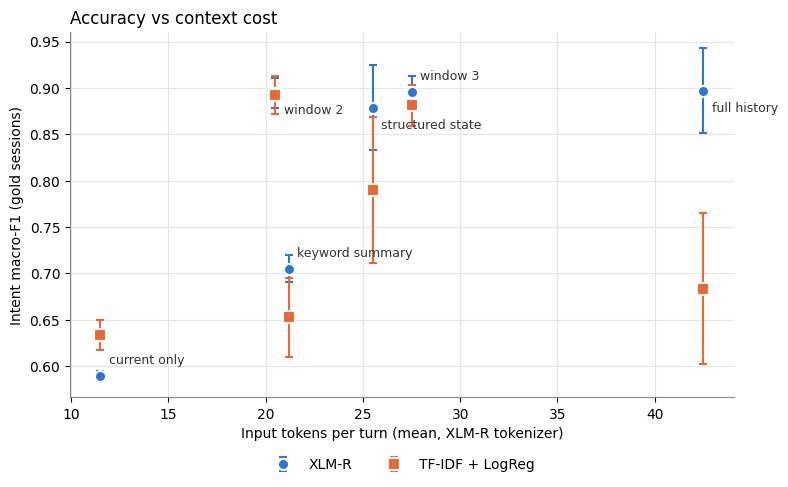

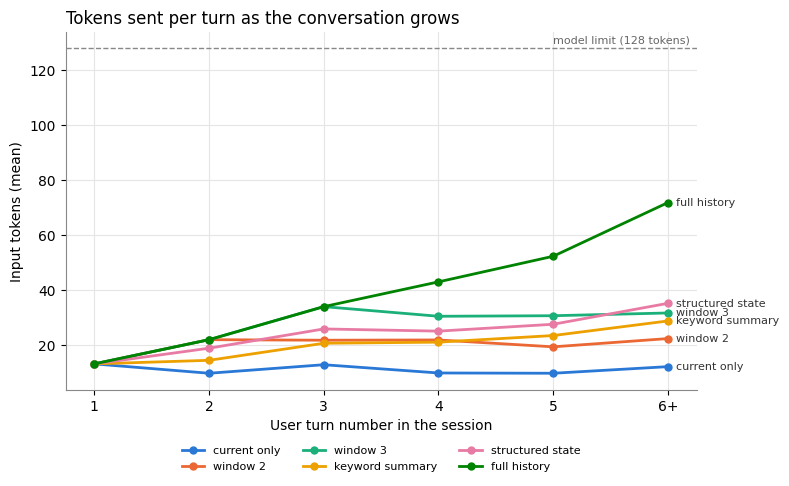

In [ ]:
import matplotlib.pyplot as plt

BLUE, ORANGE = "#2a78d6", "#eb6834"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#888", "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.8})

fig, ax = plt.subplots(figsize=(8, 5))
for model_name, colour, marker, label in [("xlmr", BLUE, "o", "XLM-R"), ("tfidf", ORANGE, "s", "TF-IDF + LogReg")]:
    xs_ = [summary[st]["tokens"]["gold_sessions"]["mean"] for st in summary]
    ms = [summary[st][f"{model_name}/gold_sessions"]["macro_f1"] for st in summary]
    ax.errorbar(xs_, [m[0] for m in ms], yerr=[m[1] for m in ms], fmt=marker, color=colour, ms=8, capsize=3,
                lw=1.5, label=label, markeredgecolor="white", markeredgewidth=1.5)
    if model_name == "xlmr":     # strategy names next to the XLM-R points, alternating above/below so they don't collide
        for k, (st, x_, m) in enumerate(sorted(zip(summary, xs_, ms), key=lambda z: z[1])):
            ax.annotate(st.replace("_", " "), (x_, m[0]), textcoords="offset points",
                        xytext=(6, 9 if k % 2 == 0 else -15), fontsize=9, color="#333")
ax.set_xlabel("Input tokens per turn (mean, XLM-R tokenizer)")
ax.set_ylabel("Intent macro-F1 (gold sessions)")
ax.set_title("Accuracy vs context cost", loc="left", fontsize=12)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
fig.tight_layout()
chart1 = os.path.join(OUT_DIR, f"context_tradeoff_e{EPOCHS}.png")
fig.savefig(chart1, dpi=200)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
positions = sorted({p for st in summary for p in summary[st]["tokens_by_position_gold_sessions"]}, key=lambda p: (len(p), p))
for colour, st in zip(SERIES, summary):
    tp = summary[st]["tokens_by_position_gold_sessions"]
    ys_ = [tp.get(p) for p in positions]
    ax.plot(positions, ys_, color=colour, lw=2, marker="o", ms=5, label=st.replace("_", " "))
    ax.annotate(st.replace("_", " "), (positions[-1], ys_[-1]), textcoords="offset points", xytext=(6, 0),
                fontsize=8, color="#333", va="center")
ax.axhline(MAX_LEN, color="#888", lw=1, ls="--")
ax.text(0.99, MAX_LEN + 2, f"model limit ({MAX_LEN} tokens)", fontsize=8, color="#666", ha="right",
        transform=ax.get_yaxis_transform())
ax.set_xlabel("User turn number in the session")
ax.set_ylabel("Input tokens (mean)")
ax.set_title("Tokens sent per turn as the conversation grows", loc="left", fontsize=12)
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3)
fig.tight_layout()
chart2 = os.path.join(OUT_DIR, f"context_token_growth_e{EPOCHS}.png")
fig.savefig(chart2, dpi=200)
plt.show()

## Download
Downloads the results file and the two charts. Put them in `research/results/`.
(They are also in Google Drive under `MyDrive/c1_context/`.)

In [ ]:
try:
    from google.colab import files
    for p in (RESULTS_PATH, chart1, chart2):
        files.download(p)
except ImportError:
    print("Files are in", OUT_DIR)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>